# IP-Adapter + ControlNet Canny

In [4]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
sys.path.insert(0, str(PROJECT_ROOT / "src"))

In [5]:
import json
from importlib.metadata import version
from textwrap import fill

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
from PIL import Image, ImageOps
from tqdm.auto import tqdm

from style_transfer.data import download_coco_images, download_dali_images
from style_transfer.generation import (
    BASE_MODEL,
    CONTROLNET_MODEL,
    IMAGE_SIZE,
    IP_ADAPTER_MODEL,
    IP_ADAPTER_WEIGHT,
    generate_image,
    load_pipeline,
    make_canny_image,
    prepare_image,
    seed_everything,
)
from style_transfer.metrics import DINO_MODEL, canny_f1, dino_cosine, load_dino

In [6]:
DEVICE = "mps"
SEED = 42
seed_everything(SEED)
PHOTO_COUNT = 24
CANNY_TOLERANCE = 3
DATA_DIR = PROJECT_ROOT / "data"
COCO_DIR = DATA_DIR / "coco"
DALI_DIR = DATA_DIR / "dali"
MODELS_DIR = PROJECT_ROOT / "models"
OUTPUT_DIR = PROJECT_ROOT / "outputs" / "ip_adapter_baseline"

## Загрузка

In [ ]:
photos = download_coco_images(COCO_DIR, count=PHOTO_COUNT, seed=SEED)
styles = download_dali_images(DALI_DIR)

print(f"Фотографии: {len(photos)}, каталог: {COCO_DIR}")
print(f"Картины Дали: {len(styles)}, каталог: {DALI_DIR}")

## Просмотр изображений

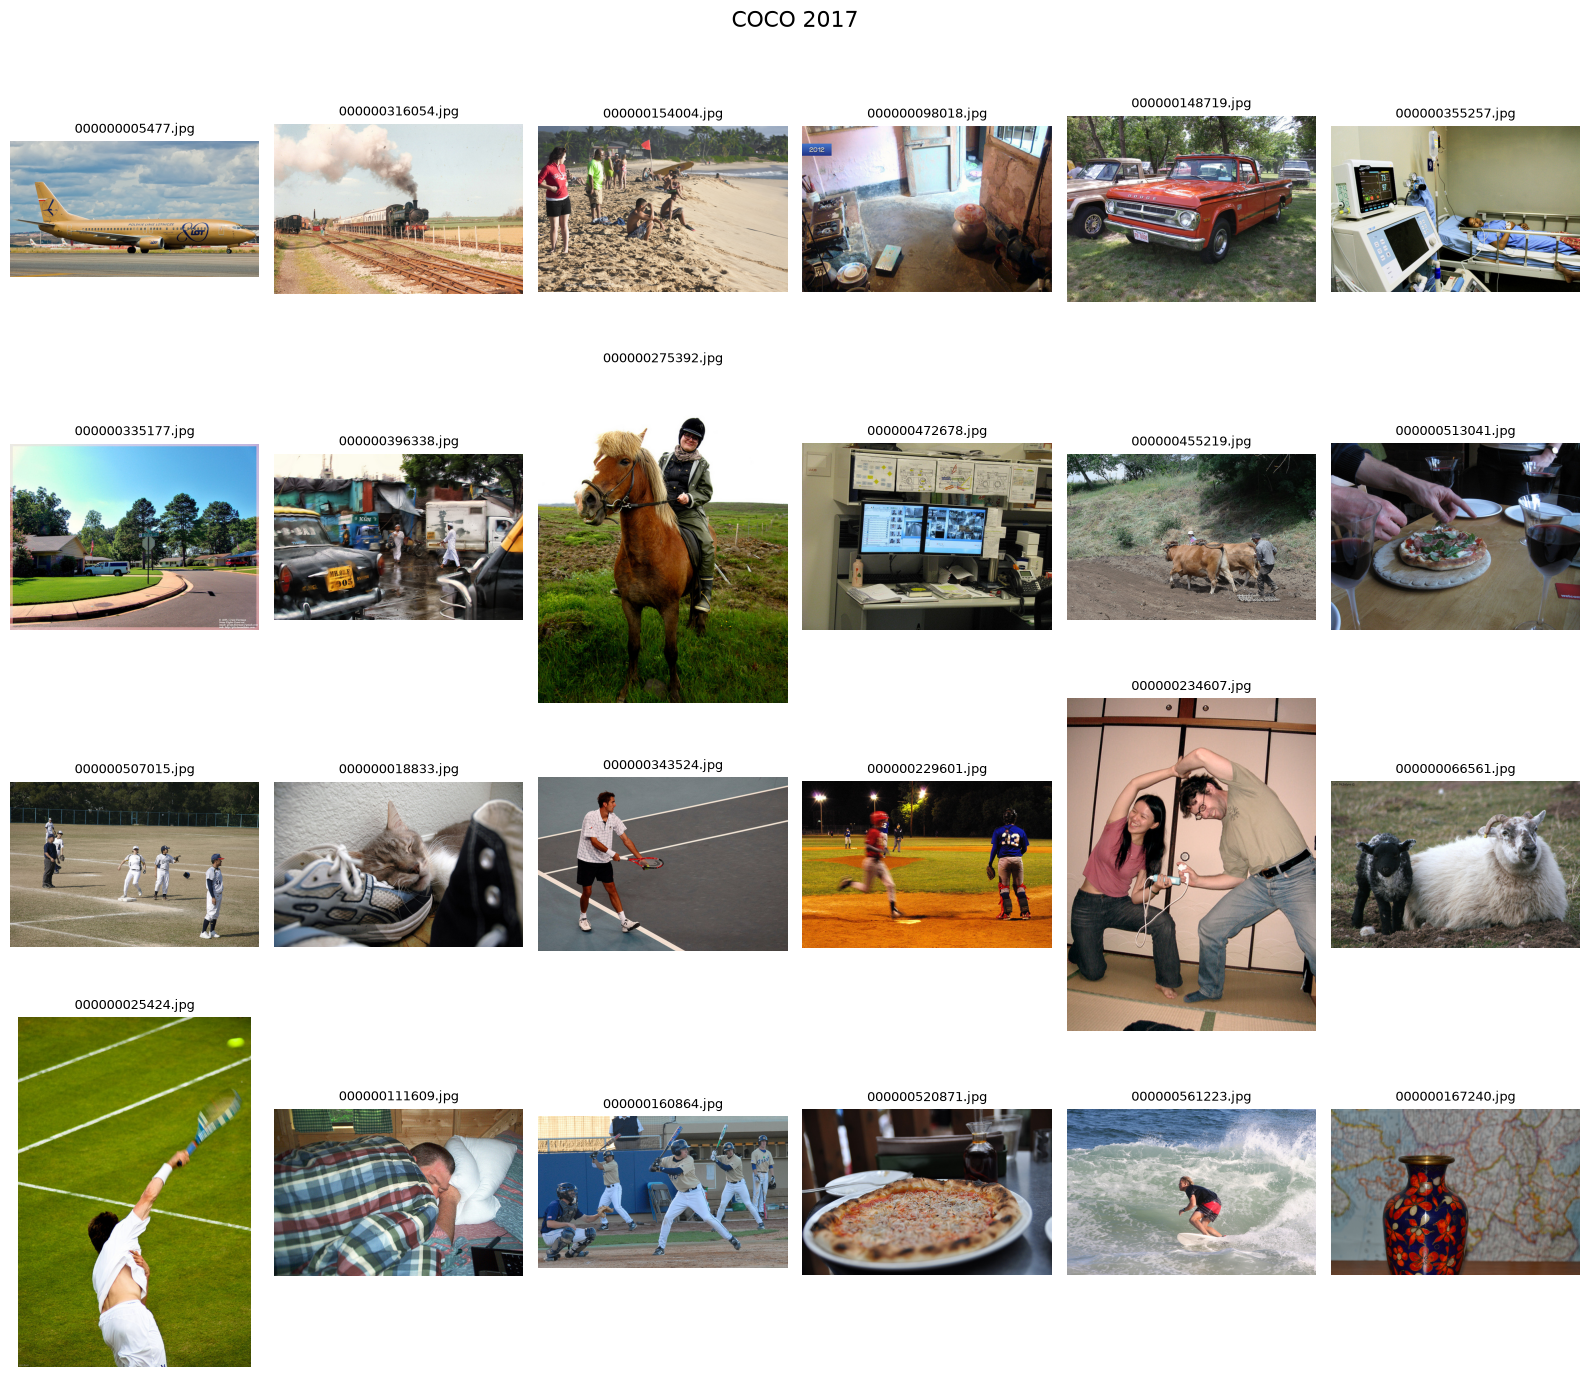

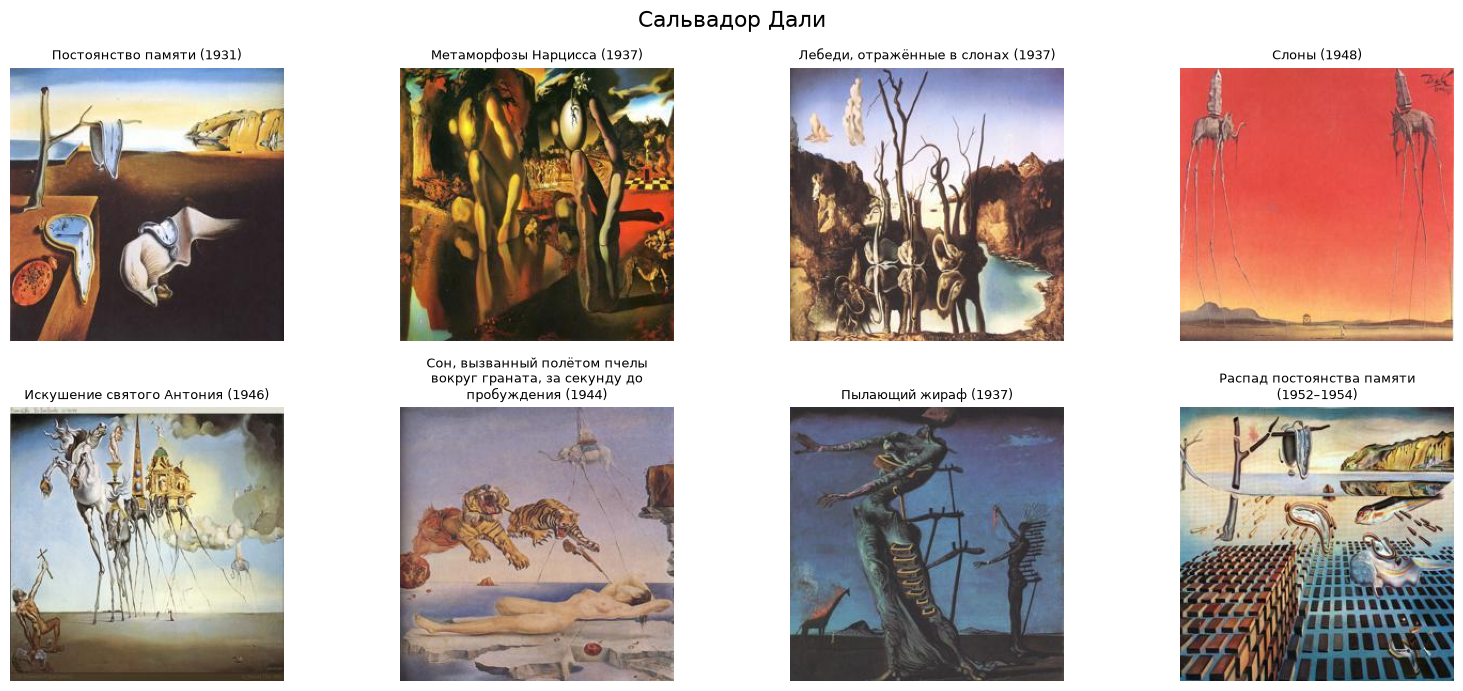

In [9]:
for directory, records, columns, heading in [
    (COCO_DIR, photos, 6, "COCO 2017"),
    (DALI_DIR, styles, 4, "Сальвадор Дали"),
]:
    rows = (len(records) + columns - 1) // columns
    fig, axes = plt.subplots(rows, columns, figsize=(16, 3.5 * rows), squeeze=False)
    fig.suptitle(heading, fontsize=16)
    for axis in axes.flat:
        axis.axis("off")
    for axis, record in zip(axes.flat, records, strict=False):
        with Image.open(directory / record["file_name"]) as image:
            axis.imshow(image.convert("RGB"))
        title = record["file_name"]
        if "title_ru" in record:
            title = f"{record['title_ru']} ({record['year']})"
        axis.set_title(fill(title, width=34), fontsize=9)
    plt.tight_layout()
    plt.show()

## Пара для первого запуска

In [10]:
photo_index = 0
style_index = 0

photo_path = COCO_DIR / photos[photo_index]["file_name"]
style_path = DALI_DIR / styles[style_index]["file_name"]
prompt = f"A painting of {photos[photo_index]['captions'][0]}"

print("Фотография:", photo_path.name)
print("Референс:", styles[style_index]["title_ru"], styles[style_index]["year"])
print("Источник:", styles[style_index]["source_url"])
print("Промпт:", prompt)

Фотография: 000000005477.jpg
Референс: Постоянство памяти 1931
Источник: https://www.wikiart.org/en/salvador-dali/the-persistence-of-memory-1931
Промпт: A painting of large mustard yellow commercial airplane parked in the airport


## Подготовка входных изображений

In [11]:
GENERATION = {
    "num_inference_steps": 30,
    "guidance_scale": 7.5,
    "ip_adapter_scale": 0.7,
    "controlnet_scale": 1.0,
    "canny_low": 100,
    "canny_high": 200,
    "negative_prompt": "low quality, blurry, text, watermark",
}

with Image.open(photo_path) as image:
    photo = prepare_image(image)
with Image.open(style_path) as image:
    style_image = ImageOps.exif_transpose(image).convert("RGB")
canny_image = make_canny_image(photo, GENERATION["canny_low"], GENERATION["canny_high"])

## Загрузка моделей

In [12]:
pipe = load_pipeline(MODELS_DIR, device=DEVICE)
print("Устройство:", pipe.device, "Тип весов:", pipe.unet.dtype)

Loading pipeline components...: 100%|██████████| 7/7 [00:00<00:00, 23.98it/s]


Устройство: mps:0 Тип весов: torch.float16


## Настройки запуска

In [13]:
run_dir = OUTPUT_DIR / f"{photo_path.stem}_{style_path.stem}_seed{SEED}"
run_dir.mkdir(parents=True, exist_ok=True)

settings = {
    "device": DEVICE,
    "dtype": str(pipe.unet.dtype),
    "seed": SEED,
    "image_size": IMAGE_SIZE,
    "photo": str(photo_path.relative_to(PROJECT_ROOT)),
    "style_image": str(style_path.relative_to(PROJECT_ROOT)),
    "style_title": styles[style_index]["title"],
    "style_source": styles[style_index]["source_url"],
    "prompt": prompt,
    "models": {
        "base": BASE_MODEL,
        "controlnet": CONTROLNET_MODEL,
        "ip_adapter": IP_ADAPTER_MODEL,
        "ip_adapter_weight": IP_ADAPTER_WEIGHT,
    },
    "scheduler": type(pipe.scheduler).__name__,
    "generation": GENERATION,
    "variants": {"without_controlnet": False, "with_controlnet": True},
    "packages": {name: version(name) for name in ["torch", "diffusers", "transformers"]},
}
(run_dir / "settings.json").write_text(
    json.dumps(settings, ensure_ascii=False, indent=2), encoding="utf-8"
)

1089

## IP-Adapter с ControlNet и без него

In [14]:
results = {}
for use_controlnet in [False, True]:
    name = "with_controlnet" if use_controlnet else "without_controlnet"
    print(name)
    results[name] = generate_image(
        pipe,
        photo,
        style_image,
        prompt,
        use_controlnet=use_controlnet,
        seed=SEED,
        **GENERATION,
    )
    results[name].save(run_dir / f"{name}.png")

without_controlnet


100%|██████████| 30/30 [00:28<00:00,  1.06it/s]


with_controlnet


100%|██████████| 30/30 [00:39<00:00,  1.31s/it]


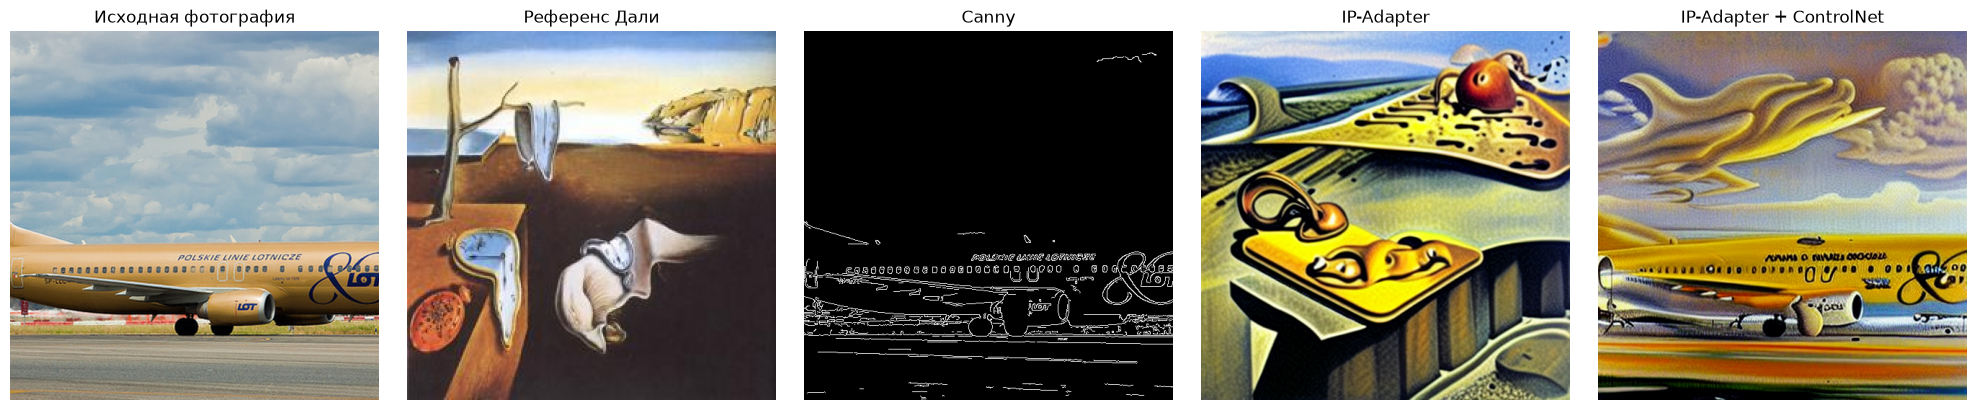

In [15]:
images = {
    "Исходная фотография": photo,
    "Референс Дали": style_image,
    "Canny": canny_image,
    "IP-Adapter": results["without_controlnet"],
    "IP-Adapter + ControlNet": results["with_controlnet"],
}
fig, axes = plt.subplots(1, len(images), figsize=(20, 4))
for axis, (title, image) in zip(axes, images.items(), strict=True):
    axis.imshow(image)
    axis.set_title(title)
    axis.axis("off")
plt.tight_layout()
fig.savefig(run_dir / "comparison.png", dpi=150, bbox_inches="tight")
plt.show()

## Средние метрики по 24 фотографиям

In [16]:
batch_dir = OUTPUT_DIR / f"coco24_{style_path.stem}_seed{SEED}"
batch_dir.mkdir(parents=True, exist_ok=True)
dino_processor, dino_model = load_dino(MODELS_DIR, device=DEVICE)

batch_settings = {
    "photos": [item["file_name"] for item in photos],
    "style_image": str(style_path.relative_to(PROJECT_ROOT)),
    "style_title": styles[style_index]["title"],
    "seed": SEED,
    "device": DEVICE,
    "models": settings["models"],
    "scheduler": settings["scheduler"],
    "generation": GENERATION,
    "dino_model": DINO_MODEL,
    "canny_tolerance": CANNY_TOLERANCE,
}
(batch_dir / "settings.json").write_text(
    json.dumps(batch_settings, ensure_ascii=False, indent=2), encoding="utf-8"
)

metric_rows = []
for item in tqdm(photos, desc="COCO"):
    with Image.open(COCO_DIR / item["file_name"]) as image:
        current_photo = prepare_image(image)
    current_prompt = f"A painting of {item['captions'][0]}"
    for variant, use_controlnet in [("without_controlnet", False), ("with_controlnet", True)]:
        generated = generate_image(
            pipe,
            current_photo,
            style_image,
            current_prompt,
            use_controlnet=use_controlnet,
            seed=SEED,
            **GENERATION,
        )
        generated.save(batch_dir / f"{Path(item['file_name']).stem}_{variant}.png")
        metric_rows.append(
            {
                "photo": item["file_name"],
                "variant": variant,
                "prompt": current_prompt,
                "canny_f1": canny_f1(
                    current_photo,
                    generated,
                    low_threshold=GENERATION["canny_low"],
                    high_threshold=GENERATION["canny_high"],
                    tolerance=CANNY_TOLERANCE,
                ),
                "dino_cosine": dino_cosine(current_photo, generated, dino_processor, dino_model),
            }
        )

metrics = pd.DataFrame(metric_rows)
metrics.to_csv(batch_dir / "metrics.csv", index=False)
mean_metrics = metrics.groupby("variant", sort=False)[["canny_f1", "dino_cosine"]].mean()
display(
    mean_metrics.rename(
        index={"without_controlnet": "IP-Adapter", "with_controlnet": "IP-Adapter + ControlNet"}
    ).round(3)
)

100%|██████████| 30/30 [00:37<00:00,  1.26s/it]
Potential NSFW content was detected in one or more images. A black image will be returned instead. Try again with a different prompt and/or seed.
100%|██████████| 30/30 [00:25<00:00,  1.16it/s]s/it]
Potential NSFW content was detected in one or more images. A black image will be returned instead. Try again with a different prompt and/or seed.
100%|██████████| 30/30 [00:25<00:00,  1.18it/s]9s/it]
Potential NSFW content was detected in one or more images. A black image will be returned instead. Try again with a different prompt and/or seed.
100%|██████████| 30/30 [00:32<00:00,  1.07s/it]
Potential NSFW content was detected in one or more images. A black image will be returned instead. Try again with a different prompt and/or seed.
100%|██████████| 30/30 [00:23<00:00,  1.29it/s]4s/it]
Potential NSFW content was detected in one or more images. A black image will be returned instead. Try again with a different prompt and/or seed.
100%|████████

,canny_f1,dino_cosine
variant,,
IP-Adapter,0.342,0.125
IP-Adapter + ControlNet,0.751,0.428
